# P2 — Random Forest y HistGradientBoosting
**Nayeli Belén Guerrero Gutierrez · Integrante 2 · Machine Learning CS3061**

Este notebook compara dos familias de ensambles bajo el objetivo móvil de P1. Incluye búsqueda temporal, métricas, curvas PR, matrices de confusión y diagnósticos de importancia. Los resultados corresponden a **validación**, no al test final.

La implementación se encuentra en `../src/experiment.py`. El protocolo está en `../PROTOCOLO.md`. La evaluación final de prueba se ejecuta por separado con `../src/evaluate_test.py` y sus resultados están en `../results/test_final/`. La comparación integrada se presenta en el README general y en el paper.

## 1. Pregunta y objetivo
Al observar el bloque $h$, ¿podemos identificar si la tasa mediana del siguiente bloque es relativamente alta?

$$\theta_h=Q_{0.75}(f_{h-1007},\ldots,f_h),\qquad y_h=\mathbf{1}[f_{h+1}>\theta_h].$$

La ventana incluye exactamente **1008 bloques hasta el actual**. No se estima el tiempo de confirmación de una transacción. La mediana se interpreta en la escala publicada por la fuente; su unidad histórica exacta no se da por verificada.



In [1]:
from pathlib import Path
import sys, os, json, hashlib
os.environ.setdefault("MPLCONFIGDIR", "/tmp/ml-p2-matplotlib")
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
import pandas as pd
from IPython.display import Image

# Funciona desde notebooks/, integrante2/ o la carpeta MACHINE.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd()/"integrante2"]
            if (p/"src/experiment.py").exists())
sys.path.insert(0, str(ROOT/"src"))
from experiment import prepare_data, CONFIGS, run, GAP
from check_protocol import main as check_protocol
print("Carpeta del experimento:", ROOT)


Carpeta del experimento: integrante2


## 2. Reproducción de P1 y control de fuga
Se usa el commit `7fbe2058c800eb5726f557b49e340bca4e338296`, rama `EDA_APARTE`, notebook `bitcoin-fee-eda-recortado/eda/01_eda.ipynb`.

El orden de operaciones importa: ordenar por altura → filtrar desde 2016 → construir siguiente bloque → calcular ventana → eliminar 1007 filas sin historia → calcular cortes 70/15/15. Los 419 727 pares iniciales se convierten en **418 720 ejemplos utilizables**.

Las comprobaciones siguientes validan hash, cortes, orientación del target y que modificar datos futuros no altere características de filas anteriores. No construyen `y_test`.


In [2]:
check_protocol()
X, y, meta, corte_train, corte_val, particiones, dataset_sha = prepare_data()
display(particiones)
print("Características:", X.shape[1])
print("Proporción alta en train:", round(y.iloc[:corte_train].mean(), 4))
print("Proporción alta en validación:", round(y.iloc[corte_train:corte_val].mean(), 4))


OK: hash, cortes P1, target siguiente, ventana inclusiva, causalidad por prefijos, balance train/validación y ausencia de y_test.
Características: 33
Proporción alta en train: 0.2465
Proporción alta en validación: 0.2147


,particion,filas,inicio_iloc,fin_iloc_exclusivo,height_inicial,height_final,fecha_inicial_utc,fecha_final_utc
0,train,293104,0,293104,392189,685292,2016-01-07 18:27:36+00:00,2021-05-28 18:08:45+00:00
1,validacion,62808,293104,355912,685293,748100,2021-05-28 18:30:10+00:00,2022-08-05 15:02:24+00:00
2,test_reservado,62808,355912,418720,748101,810908,2022-08-05 16:15:28+00:00,2023-10-06 13:37:21+00:00


## 3. Predictores y preprocesamiento
Se utilizan 33 predictores: once campos actuales, umbral y razones de comisión, rezagos, medias y desviaciones móviles, actividad por transacción, tamaño relativo al máximo reciente, intervalo entre bloques y calendario cíclico UTC.

Los cocientes de tasas usan `+1` para manejar ceros sin dividir entre cero. Los intervalos negativos pasan a faltantes y se conservan en una bandera. No se descartan extremos ni se reordenan bloques por sus marcas temporales. La imputación por mediana se ajusta **dentro de cada train**. Los árboles no requieren estandarización.

`height`, timestamp crudo, tasa siguiente y etiqueta no entran al modelo. Los detalles exactos están en el protocolo y en `causal_features`.


In [3]:
display(pd.DataFrame({"feature": X.columns,
                      "faltantes_train": X.iloc[:corte_train].isna().sum().values}))


,feature,faltantes_train
0,size,0
1,tx_count,0
2,difficulty,0
3,median_fee_rate,0
4,avg_fee_rate,0
5,total_fees,0
6,fee_range_min,0
7,fee_range_max,0
8,input_count,0
9,output_count,0


## 4. Diseño de la búsqueda temporal
Se prueban tres candidatos de cada familia en tres folds **expansivos**, con 40 000 ejemplos por validación interna y `gap=1008`.

- **Random Forest:** combina árboles bootstrap para reducir variabilidad; se controla profundidad y tamaño mínimo de hoja. Se usan 100 árboles y la mitad de los ejemplos en cada bootstrap.
- **HistGradientBoosting:** suma árboles secuenciales que corrigen la pérdida; se ajustan iteraciones, hojas, learning rate y L2. Se desactiva el holdout aleatorio de early stopping.

La selección maximiza F1 medio con umbral 0.5. Después se escoge un umbral de probabilidad usando las predicciones OOF del candidato seleccionado, sin consultar validación externa. Los resultados OOF/CV participan en el ajuste y no deben presentarse como evaluación independiente. El umbral de probabilidad es distinto de $\theta_h$.

El gap reproduce la propuesta conservadora de P1; compartir únicamente historia pasada entre ventanas no es, por sí mismo, una fuga.


In [4]:
display(pd.DataFrame([{"modelo": family, "candidato": i, **params}
                      for family, configs in CONFIGS.items()
                      for i, params in enumerate(configs)]))


,modelo,candidato,n_estimators,max_depth,min_samples_leaf,max_iter,max_leaf_nodes,learning_rate,l2_regularization
0,RandomForest,0,100.0,12.0,30,NaN,NaN,NaN,NaN
1,RandomForest,1,100.0,20.0,30,NaN,NaN,NaN,NaN
2,RandomForest,2,100.0,NaN,80,NaN,NaN,NaN,NaN
3,HistGradientBoosting,0,NaN,NaN,40,120.0,15.0,0.08,1.0
4,HistGradientBoosting,1,NaN,NaN,80,180.0,31.0,0.06,5.0
5,HistGradientBoosting,2,NaN,NaN,80,180.0,15.0,0.10,5.0


## 5. Ejecutar o cargar los resultados
La primera ejecución entrena los modelos y guarda los resultados. Si ya existen resultados completos, se muestran sin repetir los 18 ajustes de búsqueda y los dos finales. Cambiar `REENTRENAR=True` para repetirlos. Si se modifica código o datos, regenerar también los fragmentos de resultados del paper.

El conjunto de test no se evalúa en ninguna celda.


In [5]:
REENTRENAR = False
out = ROOT/"results"
manifest_path = out/"manifest.json"
if REENTRENAR or not manifest_path.exists():
    resultados = run()
else:
    manifest = json.loads(manifest_path.read_text())
    assert manifest["dataset_sha256"] == dataset_sha
    assert manifest["features"] == list(X.columns)
    assert manifest["test_evaluado"] is False
    actual_hash = hashlib.sha256((ROOT/"src/experiment.py").read_bytes()).hexdigest()
    assert manifest.get("code_sha256") == actual_hash, "El código cambió: usar REENTRENAR=True"
    resultados = pd.read_csv(out/"model_comparison.csv")
    print("Resultados existentes: no se repite entrenamiento.")
    print("Para cambios de configuración o código, usar REENTRENAR=True.")
display(pd.read_csv(out/"folds.csv"))


Resultados existentes: no se repite entrenamiento.
Para cambios de configuración o código, usar REENTRENAR=True.


,fold,train_inicio,train_fin,val_inicio,val_fin,gap
0,1,0,172095,173104,213103,1008
1,2,0,212095,213104,253103,1008
2,3,0,252095,253104,293103,1008


## 6. Búsqueda e hiperparámetros elegidos
La desviación entre folds describe diferencias entre periodos; no es un intervalo de confianza. Cada candidato se compara en los mismos tramos.


In [6]:
display(pd.read_csv(out/"busqueda_resumen.csv"))
seleccion = json.loads((out/"seleccion.json").read_text())
display(pd.DataFrame([{"modelo": name, "umbral_probabilidad": c["threshold"],
                      "f1_cv_inicial": c["f1_cv_05"], **c["params"]}
                     for name, c in seleccion.items()]))


,modelo,candidato,f1_media,f1_std,ap_media,segundos
0,HistGradientBoosting,0,0.619123,0.059840,0.742550,16.944856
1,HistGradientBoosting,1,0.627080,0.059119,0.748320,21.482088
2,HistGradientBoosting,2,0.630118,0.056193,0.746898,14.934515
3,RandomForest,0,0.579989,0.080106,0.733676,94.603944
4,RandomForest,1,0.589047,0.077703,0.738197,116.572467
5,RandomForest,2,0.581132,0.075603,0.733104,103.465954


,modelo,umbral_probabilidad,f1_cv_inicial,n_estimators,max_depth,min_samples_leaf,max_iter,max_leaf_nodes,learning_rate,l2_regularization
0,RandomForest,0.30,0.589047,100.0,20.0,30,NaN,NaN,NaN,NaN
1,HistGradientBoosting,0.35,0.630118,NaN,NaN,80,180.0,15.0,0.1,5.0


## 7. Evaluación cronológica
Los modelos finales se ajustan en las primeras **292 096 filas**, dejando 1008 como margen antes de validación. Los dos se evalúan sobre las mismas 62 808 filas posteriores. Se muestran también métricas de ajuste, claramente separadas.

La métrica principal es F1 de la clase alta. `average_precision` es AP; `pr_auc_trapezoidal` es un cálculo distinto y se identifica por separado. Las AUC usan probabilidades, mientras que F1 y la matriz usan el umbral elegido en OOF.


In [7]:
metricas = ["modelo", "particion", "f1", "precision", "recall", "average_precision",
            "pr_auc_trapezoidal", "roc_auc", "umbral", "n"]
display(resultados[metricas].round(4))


,modelo,particion,f1,precision,recall,average_precision,pr_auc_trapezoidal,roc_auc,umbral,n
0,RandomForest,train_ajuste,0.6320,0.6289,0.6351,0.7269,0.7269,0.8705,0.30,292096
1,RandomForest,validacion,0.5638,0.5966,0.5344,0.6225,0.6225,0.8171,0.30,62808
2,HistGradientBoosting,train_ajuste,0.5819,0.6360,0.5363,0.6796,0.6796,0.8264,0.35,292096
3,HistGradientBoosting,validacion,0.5713,0.5608,0.5823,0.6298,0.6298,0.8217,0.35,62808


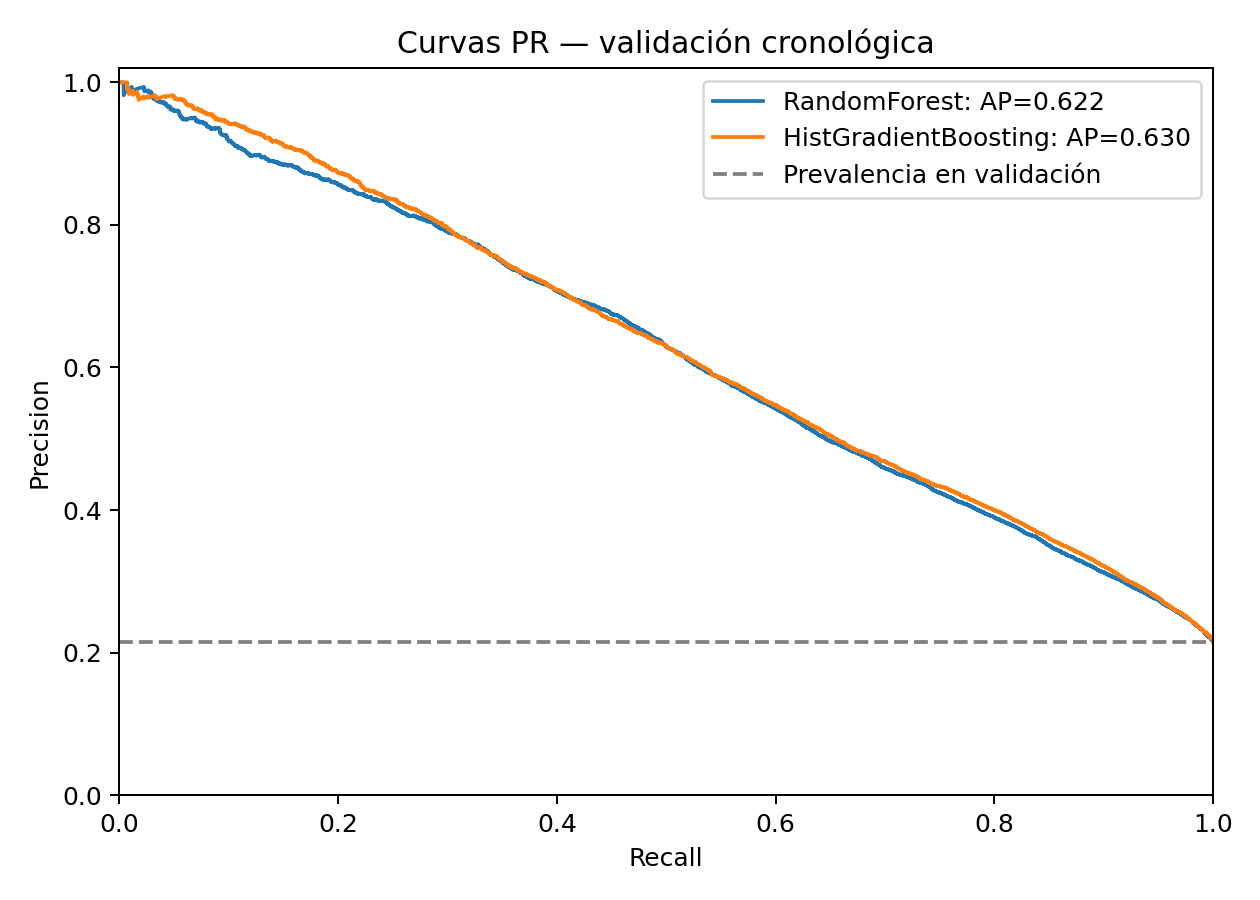

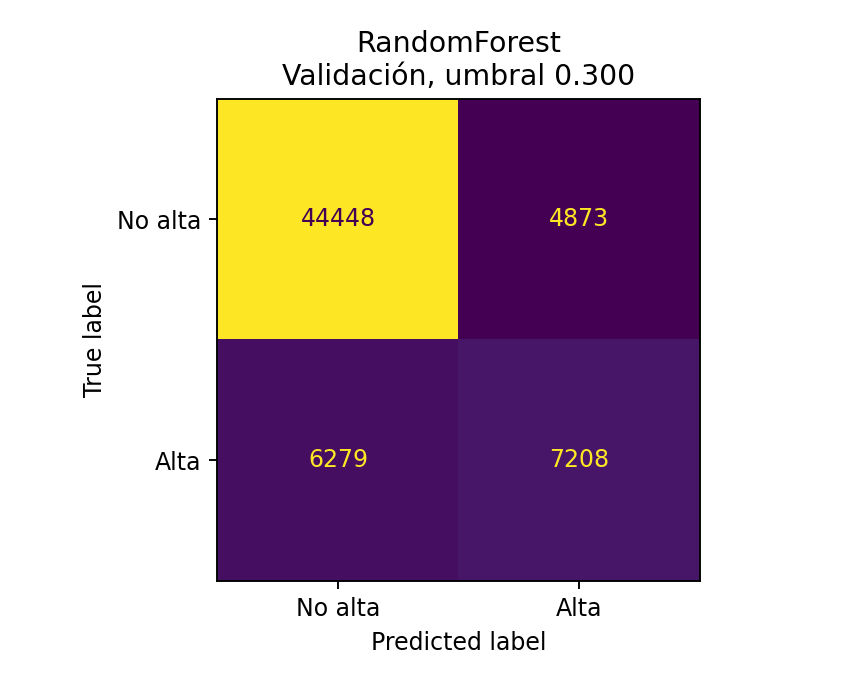

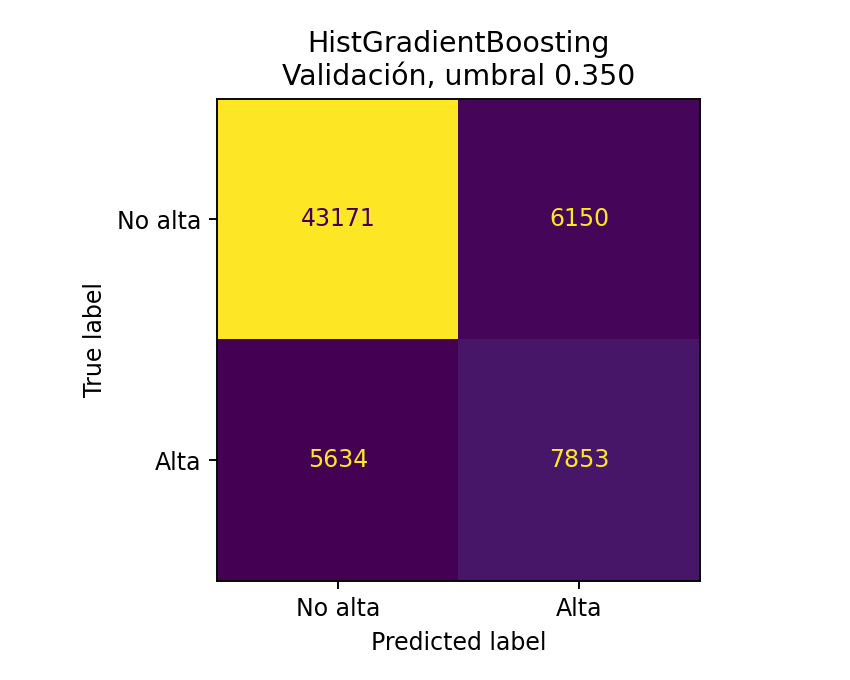

In [8]:
display(Image(filename=str(out/"figures/curvas_pr.png")))
for family in seleccion:
    display(Image(filename=str(out/"figures"/f"matriz_{family}.png")))


## 8. Brecha de generalización
Una diferencia entre train y validación es compatible tanto con sobreajuste como con cambio temporal de distribución. Por sí sola no permite separar ambos efectos. No se cambiarán los hiperparámetros después de ver esta comparación para luego presentar validación como independiente.


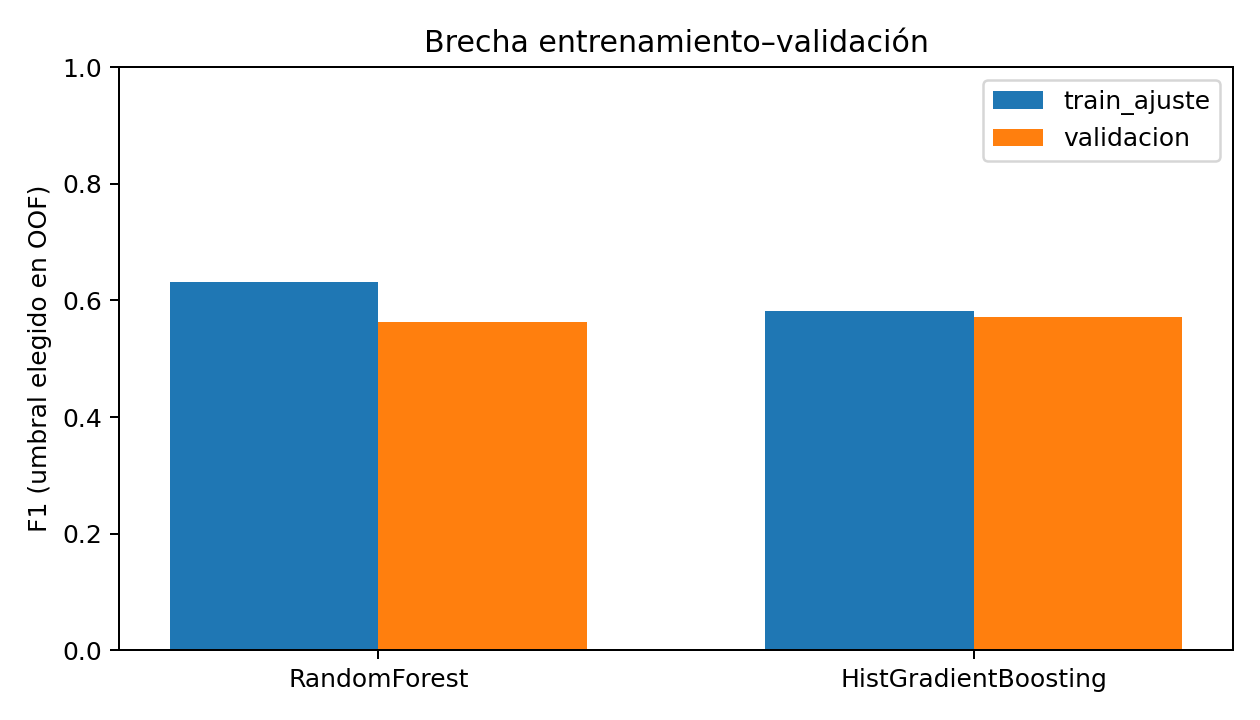

In [9]:
display(Image(filename=str(out/"figures/brecha_generalizacion.png")))


## 9. Importancia de características
Se utiliza `feature_importances_` de Random Forest, siguiendo el procedimiento de la sesión 09b, sección 10. Representa la contribución a la reducción de impureza y puede repartir crédito entre variables correlacionadas o favorecer variables de alta cardinalidad. No demuestra causalidad.

HistGradientBoosting no expone esta propiedad; su interpretación aquí usa las métricas y matrices de confusión. El ablation con reentrenamiento corresponde al integrante 3.


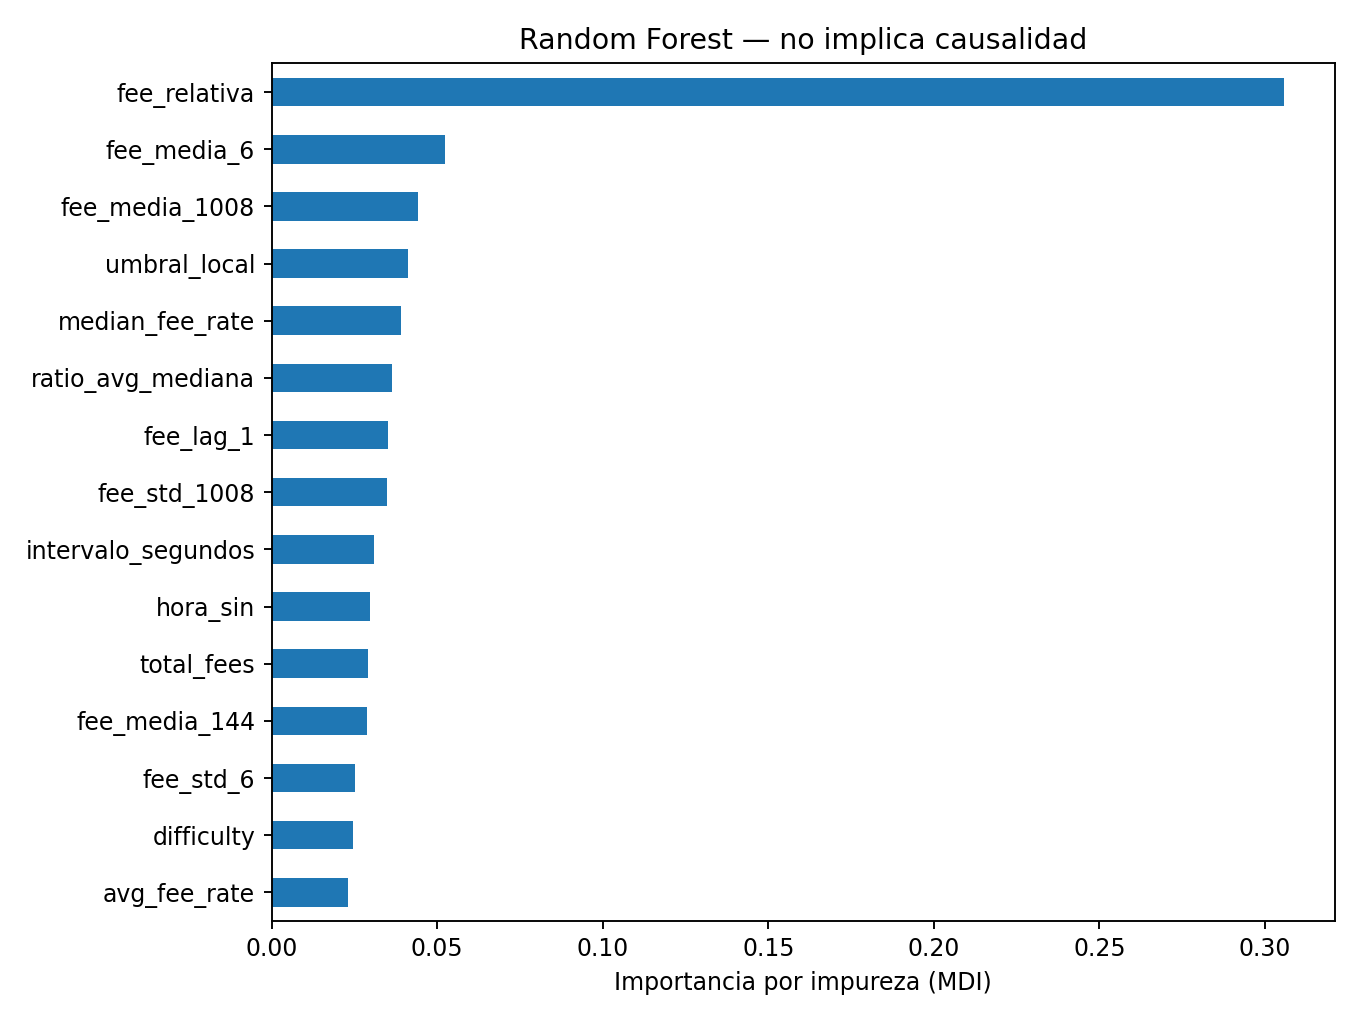

,feature,importancia_mdi
0,fee_relativa,0.305711
1,fee_media_6,0.052298
2,fee_media_1008,0.044319
3,umbral_local,0.041251
4,median_fee_rate,0.038927
5,ratio_avg_mediana,0.036404
6,fee_lag_1,0.035011
7,fee_std_1008,0.034900
8,intervalo_segundos,0.030838
9,hora_sin,0.029828


In [10]:
display(Image(filename=str(out/"figures/importancia_rf_mdi.png")))
display(pd.read_csv(out/"importancia_rf_mdi.csv").head(15))


## 10. Resultados para el paper e integración
Los fragmentos `paper/metodologia_modelos.tex` y `paper/resultados_modelos.tex` se insertan en la plantilla IEEE. Las tablas completas están en `results/`.

Este notebook presenta la comparación de RF y HGB en validación. La evaluación final de prueba está en `../results/test_final/metricas.csv`: RF obtuvo F1 0.6048 y HGB 0.6093, frente a 0.5763 de persistencia. Se conservaron los ajustes originales y los umbrales OOF, sin reajuste con validación. P1 inspeccionó distribuciones de test durante la reformulación; esa exposición histórica es una limitación del estudio.

El README general y el paper reúnen los resultados de los cuatro métodos. La logística utiliza 22 variables y los árboles 33, por lo que la comparación no aísla el efecto del algoritmo. Las diferencias observadas en prueba son descriptivas; no se ha establecido su significancia estadística.


In [11]:
validacion = resultados[resultados.particion.eq("validacion")].sort_values("f1", ascending=False)
for _, r in validacion.iterrows():
    print(f"{r['modelo']}: F1={r['f1']:.4f}, precision={r['precision']:.4f}, "
          f"recall={r['recall']:.4f}, AP={r['average_precision']:.4f}, ROC-AUC={r['roc_auc']:.4f}")
print("Comparación provisional en validación. Test reservado; baselines del integrante 1 pendientes de integrar.")


HistGradientBoosting: F1=0.5713, precision=0.5608, recall=0.5823, AP=0.6298, ROC-AUC=0.8217
RandomForest: F1=0.5638, precision=0.5966, recall=0.5344, AP=0.6225, ROC-AUC=0.8171
Comparación provisional en validación. Test reservado; baselines del integrante 1 pendientes de integrar.
